# URL text classification

The first models used URL length, domain length and digit count.
These features cannot distinguish URLs with identical measurements,
such as paypal.com and paypai.com.

This experiment uses character-level TF-IDF and SGDClassifier to
investigate whether URL text provides useful additional information.
We compare models using the same data split and validation metrics.

In [1]:
import pandas as pd

df = pd.read_csv("../data/PhiUSIIL_Phishing_URL_Dataset.csv")

urls = df["URL"]
y = df["label"]

In [2]:
from sklearn.model_selection import train_test_split

urls_train, urls_test, y_train, y_test = train_test_split(
    urls,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

urls_train, urls_val, y_train, y_val = train_test_split(
    urls_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train,
)

print("Training examples:", len(urls_train))
print("Validation examples:", len(urls_val))
print("Test examples:", len(urls_test))

Training examples: 141477
Validation examples: 47159
Test examples: 47159


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

url_text_model = make_pipeline(
    TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=3,
        max_features=100_000,
        lowercase=True,
    ),
    SGDClassifier(
        loss="log_loss",
        random_state=42,
        max_iter=1000,
    ),
)

url_text_model.fit(urls_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('sgdclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'char'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(3, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",100000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`

,Model,Validation accuracy,Phishing precision,Phishing recall,Phishing F1
0,Character TF-IDF + SGDClassifier,0.9934,1.0,0.9845,0.9922


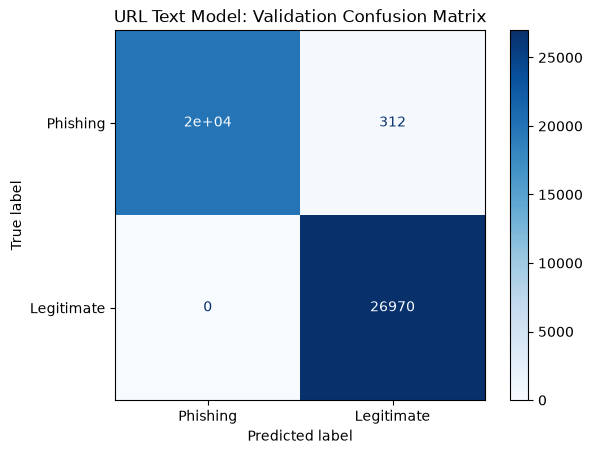

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

y_val_pred_text = url_text_model.predict(urls_val)

results = pd.DataFrame([{
    "Model": "Character TF-IDF + SGDClassifier",
    "Validation accuracy": accuracy_score(y_val, y_val_pred_text),
    "Phishing precision": precision_score(
        y_val, y_val_pred_text, pos_label=0, zero_division=0
    ),
    "Phishing recall": recall_score(
        y_val, y_val_pred_text, pos_label=0, zero_division=0
    ),
    "Phishing F1": f1_score(
        y_val, y_val_pred_text, pos_label=0, zero_division=0
    ),
}])

display(results.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_text,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues",
)

plt.title("URL Text Model: Validation Confusion Matrix")
plt.show()

In [6]:
format_examples = [
    "https://netflix.com",
    "https://www.netflix.com",
    "https://netflix.com/",
    "https://www.netflix.com/",
    "https://paypal.com",
    "https://www.paypal.com",
    "https://amazon.com",
    "https://www.amazon.com",
]

predictions = url_text_model.predict(format_examples)

display(pd.DataFrame({
    "URL": format_examples,
    "Prediction": [
        "Phishing" if prediction == 0 else "Legitimate"
        for prediction in predictions
    ],
}))

,URL,Prediction
0,https://netflix.com,Phishing
1,https://www.netflix.com,Legitimate
2,https://netflix.com/,Phishing
3,https://www.netflix.com/,Legitimate
4,https://paypal.com,Phishing
5,https://www.paypal.com,Legitimate
6,https://amazon.com,Phishing
7,https://www.amazon.com,Legitimate
